In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os

print(os.path.exists(r"C:\Users\Admin\OneDrive\Desktop\Customer.csv"))

False


In [5]:
data = pd.read_csv("C:\\Users\\Admin\\OneDrive\\Desktop\\Customer\\123.csv")

In [6]:
print("Dataset loaded successfully!")
print("Dataset Shape:", data.shape)

data.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
print("Dataset Information:")
data.info()

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

print("\nChurn Distribution:")
print(data["Churn"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [14]:
# Convert TotalCharges into numeric format
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Check missing values
print(data.isnull().sum())

# Check data types
print(data.dtypes)

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object


In [15]:
# Check customers with missing TotalCharges
data[data["TotalCharges"].isnull()][["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [16]:
data.loc[
    data["TotalCharges"].isnull() & (data["tenure"] == 0),
    "TotalCharges"
] = 0

print("Remaining Missing Values:", data["TotalCharges"].isnull().sum())

Remaining Missing Values: 0


In [17]:
churn_percentage = data["Churn"].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


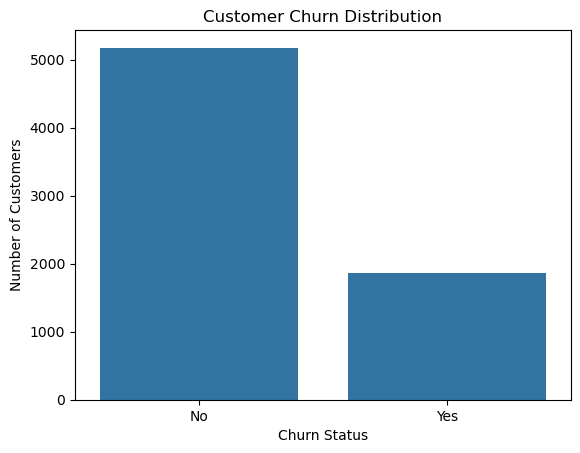

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=data, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
# Contract Type vs Churn
contract_churn = pd.crosstab(
    data["Contract"],
    data["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [20]:
# Average tenure by churn status
tenure_analysis = data.groupby("Churn")["tenure"].mean()

print(tenure_analysis.round(2))

Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


In [21]:
# Average monthly charges by churn
charges_analysis = data.groupby("Churn")["MonthlyCharges"].mean()

print(charges_analysis.round(2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


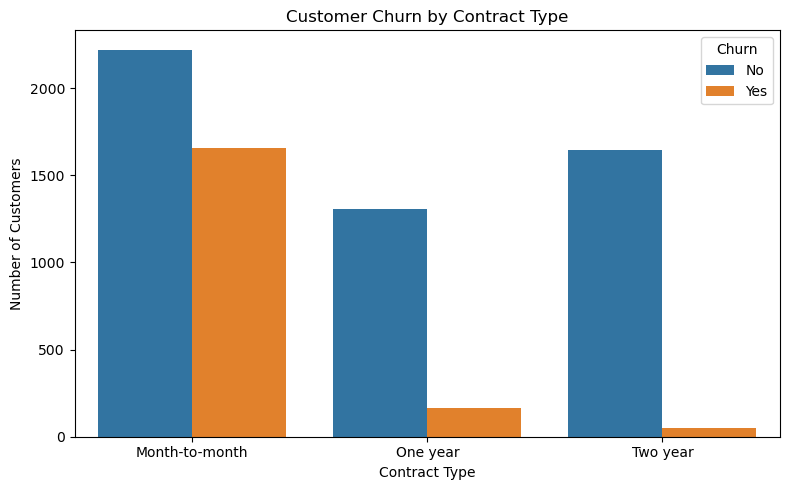

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=data, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [23]:
# Feature Engineering: Create Tenure Groups

data["TenureGroup"] = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

# Display the results
data[["tenure", "TenureGroup", "Churn"]].head(10)

,tenure,TenureGroup,Churn
0,1,0-12 Months,No
1,34,25-48 Months,No
2,2,0-12 Months,Yes
3,45,25-48 Months,No
4,2,0-12 Months,Yes
5,8,0-12 Months,Yes
6,22,13-24 Months,No
7,10,0-12 Months,No
8,28,25-48 Months,Yes
9,62,49-72 Months,No


In [24]:
# Analyze churn percentage by tenure group

tenure_churn = pd.crosstab(
    data["TenureGroup"],
    data["Churn"],
    normalize="index"
) * 100

print(tenure_churn.round(2))

Churn            No    Yes
TenureGroup               
0-12 Months   52.56  47.44
13-24 Months  71.29  28.71
25-48 Months  79.61  20.39
49-72 Months  90.49   9.51


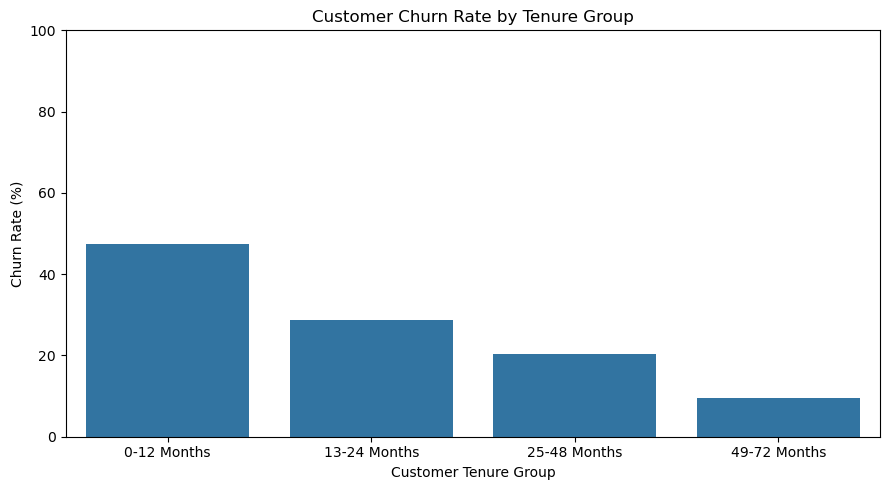

In [25]:
#Tenure Group ka graph
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn["Yes"]
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [26]:
# Check all column names
print("Dataset Columns:")
print(data.columns.tolist())

print("\nDataset Shape:")
print(data.shape)

print("\nData Types:")
print(data.dtypes)

Dataset Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup']

Dataset Shape:
(7043, 22)

Data Types:
customerID            object
gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn                 ob

In [35]:
# Separate input features (X) and target variable (y)

X = data.drop(columns=["customerID", "Churn", "TenureGroup"])
y = data["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [34]:
# Convert categorical columns into numerical columns

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Original Features Shape:", X.shape)
print("Encoded Features Shape:", X_encoded.shape)

print("\nFirst 5 Rows of Encoded Data:")
display(X_encoded.head())



Original Features Shape: (7043, 19)
Encoded Features Shape: (7043, 30)

First 5 Rows of Encoded Data:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [33]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes of the datasets
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)



Training Features: (5634, 30)
Testing Features: (1409, 30)
Training Target: (5634,)
Testing Target: (1409,)


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict churn for test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Training Completed Successfully!")
print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Training Completed Successfully!
Model Accuracy: 80.34 %


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(max_iter=2000, random_state=42)

model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Training Completed!")
print("Model Accuracy:", round(accuracy * 100, 2), "%")



Model Training Completed!
Model Accuracy: 80.7 %


In [38]:
from sklearn.metrics import classification_report, confusion_matrix

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[925 110]
 [162 212]]


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train a balanced Logistic Regression model
balanced_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

balanced_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_balanced = balanced_model.predict(X_test_scaled)

# Evaluate the model
print("Balanced Logistic Regression Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

Balanced Logistic Regression Results
Accuracy: 74.02 %

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[749 286]
 [ 80 294]]


In [40]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_dt) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Results
Accuracy: 73.46 %

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.71      0.80      1035
         Yes       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409

Confusion Matrix:
[[733 302]
 [ 72 302]]


In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Results
Accuracy: 76.22 %

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.78      0.83      1035
         Yes       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

Confusion Matrix:
[[803 232]
 [103 271]]


In [42]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Compare all four models
models = {
    "Logistic Regression": (model, X_test_scaled),
    "Balanced Logistic Regression": (balanced_model, X_test_scaled),
    "Decision Tree": (dt_model, X_test),
    "Random Forest": (rf_model, X_test)
}

results = []

for name, (trained_model, test_features) in models.items():

    predictions = trained_model.predict(test_features)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Churn Precision (%)": round(
            precision_score(y_test, predictions, pos_label="Yes") * 100, 2
        ),
        "Churn Recall (%)": round(
            recall_score(y_test, predictions, pos_label="Yes") * 100, 2
        ),
        "Churn F1-Score (%)": round(
            f1_score(y_test, predictions, pos_label="Yes") * 100, 2
        )
    })

comparison_df = pd.DataFrame(results)

print("Final Model Comparison:")
display(comparison_df)

Final Model Comparison:


,Model,Accuracy (%),Churn Precision (%),Churn Recall (%),Churn F1-Score (%)
0,Logistic Regression,80.70,65.84,56.68,60.92
1,Balanced Logistic Regression,74.02,50.69,78.61,61.64
2,Decision Tree,73.46,50.00,80.75,61.76
3,Random Forest,76.22,53.88,72.46,61.80


In [43]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Churn Factors:")
display(feature_importance.head(10))

Top 10 Important Churn Factors:


,Feature,Importance
25,Contract_Two year,0.405269
24,Contract_One year,0.253452
10,InternetService_Fiber optic,0.111558
1,tenure,0.094694
23,StreamingMovies_Yes,0.034102
3,TotalCharges,0.027222
28,PaymentMethod_Electronic check,0.020621
2,MonthlyCharges,0.019440
11,InternetService_No,0.015233
7,PhoneService_Yes,0.012017


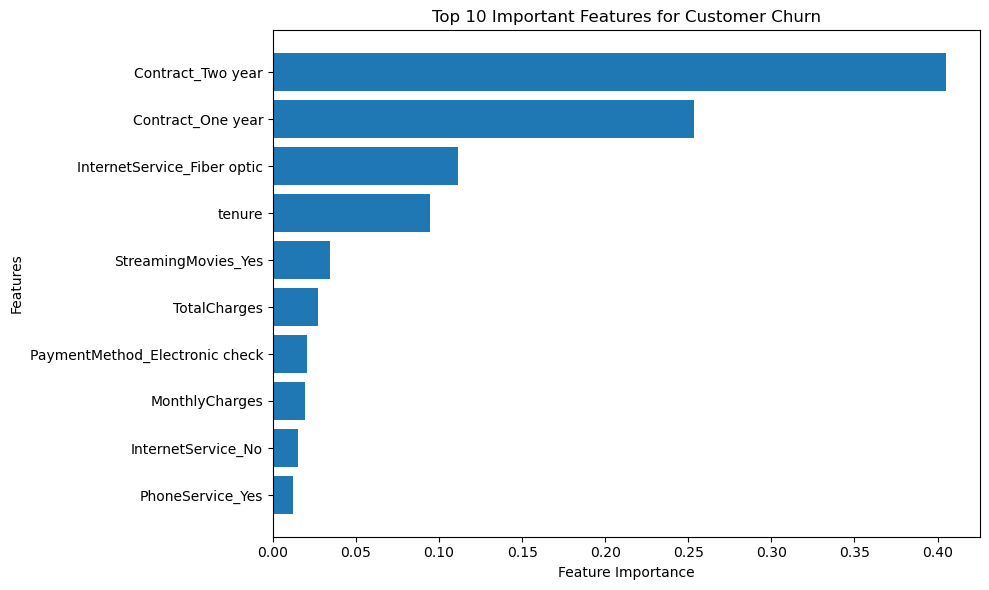

In [44]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Important Features for Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [45]:
# Create a copy of the test dataset
retention_analysis = X_test.copy()

# Add actual churn status
retention_analysis["Actual_Churn"] = y_test.values

# Add Decision Tree predictions
retention_analysis["Predicted_Churn"] = y_pred_dt

# Select customers predicted to churn
at_risk_customers = retention_analysis[
    retention_analysis["Predicted_Churn"] == "Yes"
].copy()

print("Total customers predicted to churn:",
      len(at_risk_customers))

print("\nFirst 10 at-risk customer records:")
display(at_risk_customers.head(10))

Total customers predicted to churn: 604

First 10 at-risk customer records:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Actual_Churn,Predicted_Churn
2280,1,8,100.15,908.55,0,0,0,1,0,1,...,0,1,0,0,1,1,0,0,No,Yes
4460,0,18,78.20,1468.75,1,1,0,1,0,0,...,0,0,0,0,0,0,1,0,No,Yes
5748,0,21,99.85,1992.55,0,0,0,1,0,1,...,0,1,0,0,1,1,0,0,No,Yes
3568,0,21,99.15,1956.40,0,0,0,1,0,0,...,0,1,0,0,1,0,0,0,No,Yes
2079,0,70,106.05,7554.05,1,1,1,1,0,1,...,0,1,0,0,1,0,1,0,No,Yes
667,0,49,30.20,1453.10,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,No,Yes
3524,1,11,84.80,906.85,0,0,0,1,0,1,...,0,1,0,0,1,1,0,0,Yes,Yes
2136,0,15,91.00,1430.05,1,0,1,1,0,1,...,0,0,0,0,1,0,1,0,No,Yes
6529,1,2,74.85,156.40,1,0,0,1,0,1,...,0,0,0,0,1,0,0,1,Yes,Yes
1242,0,21,28.50,629.35,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,No,Yes


## 1. Business Recommendations

Based on the Exploratory Data Analysis (EDA) and Customer Churn Prediction results, the following business recommendations are suggested to improve customer retention.

### 1. Focus on Month-to-Month Customers

The analysis shows that the churn rate for month-to-month customers is 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

**Recommendation:** The company should offer suitable long-term plans, loyalty benefits, and contract renewal incentives to month-to-month customers.

### 2. Improve Customer Onboarding

Customers with a tenure of 0–12 months have a churn rate of 47.44%. This indicates that the first year is an important period for customer retention.

**Recommendation:** The company should provide better onboarding, timely follow-ups, clear service information, and early-stage customer support.

### 3. Review Monthly Charges and Perceived Value

The average monthly charge for churned customers is $74.44, compared with $61.27 for customers who stayed.

**Recommendation:** The company should review pricing plans, explain the value of its services, and offer suitable packages based on customer needs. These results show an association, but do not prove that higher charges cause churn.

### 4. Use Machine Learning to Identify At-Risk Customers

The Decision Tree model achieved approximately 80.75% recall for churn customers. It can help identify customers who may be at risk of leaving.

**Recommendation:** The company should use the model to create a list of potentially at-risk customers and prioritize them for follow-up. Predictions should be verified rather than treated as confirmed churn.

### 5. Design Targeted Retention Campaigns

Different customer groups may have different reasons for leaving the company.

**Recommendation:** The company should design relevant retention offers, service improvements, and personalized communication based on customer characteristics and service usage.

### 6. Monitor Retention Performance

Retention campaigns should be evaluated to understand whether they are effective.

**Recommendation:** The company should regularly monitor churn rate, customer retention rate, campaign response rate, customer satisfaction, and retention campaign costs. Small pilot campaigns can help evaluate the impact before wider implementation.

### Summary

The analysis suggests that the company should prioritize early-tenure and month-to-month customers, review pricing and service value, and use churn predictions to guide retention activities. These actions should be tested and monitored to determine their actual business impact.


## Final Conclusion

This project, titled **Customer Churn Prediction and Retention Analytics**, focuses on understanding customer churn and identifying customers who may be at risk of leaving a service provider.

The Telco Customer Churn dataset was analyzed using data cleaning, exploratory data analysis (EDA), feature engineering, and machine learning techniques. The analysis identified important patterns related to contract type, customer tenure, and monthly charges.

The results showed that month-to-month customers had a churn rate of 42.71%, while customers with a tenure of 0–12 months had a churn rate of 47.44%. These findings indicate that early customer engagement and contract-related retention strategies deserve attention.

Four machine learning models were evaluated: Logistic Regression, Balanced Logistic Regression, Decision Tree, and Random Forest. Logistic Regression achieved the highest accuracy of 80.70%, while the Decision Tree achieved the highest churn recall of 80.75%.

The project demonstrates how data analytics and machine learning can support customer retention decisions. The findings can help businesses identify potentially at-risk customers, design targeted retention campaigns, and monitor customer behaviour.

However, model predictions are not always correct. The model should therefore be tested and monitored before being used for real business decisions. Future improvements could include model tuning, additional customer data, and evaluating retention campaign effectiveness.

Overall, this project provides a data-driven approach to understanding customer churn and supporting retention planning.
